In [1]:
"""
Minimal working code to read CT DICOM files, RTDOSE, and RTSTRUCT files.
Based on the DL_NTCP_Xerostomia GitHub repository approach.

Requirements:
    pip install pydicom SimpleITK numpy --break-system-packages
"""

import os
import numpy as np
import pydicom
import SimpleITK as sitk
from pathlib import Path
from rt_utils import RTStructBuilder


## load a CT and RTDOSE

In [42]:
def convert_image_to_numpy(image):
    # helper function, extracts a numpy array from an SimpleITK image
    return sitk.GetArrayFromImage(image)


def check_frame_of_reference_uid(ct_folder, rtdose_file, rtstruct_file):
    """
    Check if CT, RTDOSE, and RTSTRUCT have matching Frame of Reference UID.
    This is crucial for proper registration.
    
    Args:
        ct_folder: Path to CT DICOM folder
        rtdose_file: Path to RTDOSE file
        rtstruct_file: Path to RTSTRUCT file
        
    Returns:
        bool: True if all UIDs match
    """
    print("\nChecking Frame of Reference UIDs...")
    
    # Get CT UID (from first slice)
    ct_files = [f for f in os.listdir(ct_folder) if f.endswith('.dcm') or not '.' in f]
    if ct_files:
        ct_ds = pydicom.dcmread(os.path.join(ct_folder, ct_files[0]))
        ct_uid = ct_ds.FrameOfReferenceUID if hasattr(ct_ds, 'FrameOfReferenceUID') else None
    else:
        ct_uid = None
    
    # Get RTDOSE UID
    dose_ds = pydicom.dcmread(rtdose_file)
    dose_uid = dose_ds.FrameOfReferenceUID if hasattr(dose_ds, 'FrameOfReferenceUID') else None
    
    # Get RTSTRUCT UID
    struct_ds = pydicom.dcmread(rtstruct_file)
    struct_uid = struct_ds.ReferencedFrameOfReferenceSequence[0].FrameOfReferenceUID if hasattr(struct_ds, 'ReferencedFrameOfReferenceSequence') else None
    
    print(f"CT Frame of Reference UID: {ct_uid}")
    print(f"RTDOSE Frame of Reference UID: {dose_uid}")
    print(f"RTSTRUCT Frame of Reference UID: {struct_uid}")
    
    match = (ct_uid == dose_uid == struct_uid)
    print(f"UIDs match: {match}")
    
    return match


def read_ct_dicom_series(ct_folder_path):
    """
    Read CT DICOM series from a folder.
    
    Args:
        ct_folder_path: Path to folder containing CT DICOM slices
        
    Returns:
        ct_array: 3D numpy array with shape (num_slices, height, width)
        ct_image: SimpleITK image object with metadata (spacing, origin, direction)
    """
    print(f"Reading CT DICOM series from: {ct_folder_path}")
    
    # Get DICOM file names
    reader = sitk.ImageSeriesReader()
    dicom_names = reader.GetGDCMSeriesFileNames(ct_folder_path)
    
    if not dicom_names:
        raise ValueError(f"No DICOM files found in {ct_folder_path}")
    
    print(f"Found {len(dicom_names)} CT slices")
    
    # Read the series
    reader.SetFileNames(dicom_names)
    ct_image = reader.Execute()
    
    print(f"CT array shape: {ct_image.GetSize()}")
    print(f"CT spacing: {ct_image.GetSpacing()}")  # (x, y, z)
    print(f"CT origin: {ct_image.GetOrigin()}")
    
    return ct_image


def read_rtdose_dicom(rtdose_file_path, ct_image=None):
    """
    Read RTDOSE DICOM file.
    
    Args:
        rtdose_file_path: Path to RTDOSE DICOM file
        ct_image: Optional CT image for registration/resampling
        
    Returns:
        dose_array: 3D numpy array with dose values in cGy
        dose_image: SimpleITK image object
    """
    print(f"\nReading RTDOSE from: {rtdose_file_path}")
    
    # Read RTDOSE using SimpleITK
    dose_image = sitk.ReadImage(rtdose_file_path)
    
    # Read with pydicom to get dose grid scaling
    ds = pydicom.dcmread(rtdose_file_path)
    dose_grid_scaling = float(ds.DoseGridScaling)
    
    print(f"RTDOSE array shape: {dose_image.GetSize()}")
    dose_arrary = sitk.GetArrayFromImage(dose_image)
    dose_array = dose_arrary * dose_grid_scaling * 100  # to cGy
    print(f"RTDOSE min/max: {dose_array.min():.2f} / {dose_array.max():.2f} cGy")
    print(f"RTDOSE spacing: {dose_image.GetSpacing()}")
    
    # Optionally resample RTDOSE to CT grid
    if ct_image is not None:
        print("Resampling RTDOSE to CT grid...")
        dose_image_resampled = resample_to_reference(dose_image, ct_image)
        
        print(f"Resampled RTDOSE shape: {dose_image_resampled.GetSize()}")
        return dose_image_resampled
    
    return dose_array, dose_image


def resample_to_reference(moving_image, reference_image, interpolator=sitk.sitkLinear):
    """
    Resample moving image to match reference image grid.
    
    Args:
        moving_image: SimpleITK image to resample (e.g., RTDOSE)
        reference_image: SimpleITK reference image (e.g., CT)
        interpolator: Interpolation method
        
    Returns:
        resampled_image: SimpleITK image resampled to reference grid
    """
    resampler = sitk.ResampleImageFilter()
    resampler.SetReferenceImage(reference_image)
    resampler.SetInterpolator(interpolator)
    resampler.SetDefaultPixelValue(0)
    resampler.SetOutputPixelType(moving_image.GetPixelID())
    
    resampled_image = resampler.Execute(moving_image)
    return resampled_image




def read_rtstruct_with_rtutils(rtstruct_file_path, ct_folder_path):
    """
    Read RTSTRUCT using rt-utils library (recommended approach).
    
    Args:
        rtstruct_file_path: Path to RTSTRUCT DICOM file
        ct_folder_path: Path to CT DICOM folder
        
    Returns:
        masks_dict: Dictionary of structure names to binary masks
        structure_names: List of structure names
    """
    print(f"\nReading RTSTRUCT with rt-utils from: {rtstruct_file_path}")
    
    # Load RTSTRUCT
    rtstruct = RTStructBuilder.create_from(
        dicom_series_path=ct_folder_path,
        rt_struct_path=rtstruct_file_path
    )
    
    # Get all structure names
    structure_names = rtstruct.get_roi_names()
    print(f"Found {len(structure_names)} structures: {structure_names}")
    
    # Extract masks for each structure
    masks_dict = {}
    for roi_name in structure_names:
        mask = rtstruct.get_roi_mask_by_name(roi_name)
        masks_dict[roi_name] = mask
        voxel_count = np.sum(mask)
        print(f"  {roi_name}: {voxel_count} voxels")
    
    return masks_dict, structure_names



def create_combined_segmentation_map(masks_dict, structure_priority=None):
    """
    Combine individual structure masks into a single segmentation map.
    
    Args:
        masks_dict: Dictionary mapping structure names to binary masks
        structure_priority: Optional list defining structure priority (first = highest)
                          If None, uses alphabetical order
        
    Returns:
        segmentation_map: 3D array with integer labels for each structure
        label_to_structure: Dictionary mapping label values to structure names
    """
    print("\nCreating combined segmentation map...")
    
    if not masks_dict:
        raise ValueError("No masks provided")
    
    # Get shape from first mask
    shape = next(iter(masks_dict.values())).shape
    segmentation_map = np.zeros(shape, dtype=np.uint16)
    
    # Determine structure order
    if structure_priority is None:
        structure_order = sorted(masks_dict.keys())
    else:
        # Use priority list, then add any remaining structures
        structure_order = [s for s in structure_priority if s in masks_dict]
        structure_order += [s for s in masks_dict.keys() if s not in structure_order]
    
    # Assign labels (reverse order so highest priority overwrites)
    label_to_structure = {0: 'background'}
    for idx, structure_name in enumerate(reversed(structure_order), start=1):
        label = len(structure_order) - idx + 1
        mask = masks_dict[structure_name]
        segmentation_map[mask > 0] = label
        label_to_structure[label] = structure_name
        print(f"  Label {label}: {structure_name}")
    
    print(f"Segmentation map shape: {segmentation_map.shape}")
    print(f"Unique labels: {np.unique(segmentation_map)}")

    segmentation_map = np.transpose(segmentation_map, (2, 1, 0))
    # rotate 90 degrees to match (x,y,z) orientation
    segmentation_map = np.swapaxes(segmentation_map, 1, 2)
    print(f"Segmentation map transposed shape: {segmentation_map.shape}")
    
    return segmentation_map, label_to_structure


def convert_segmentation_map_to_image(segmentation_map, reference_image):
    """
    Convert segmentation map numpy array to SimpleITK image with reference metadata.
    
    Args:
        segmentation_map: 3D numpy array with integer labels
        reference_image: SimpleITK image to copy metadata from (i.e. CT image)
        
    Returns:
        segmentation_image: SimpleITK image with segmentation data
    """
    segmentation_image = sitk.GetImageFromArray(segmentation_map.astype(np.uint16))
    segmentation_image.SetSpacing(reference_image.GetSpacing())
    segmentation_image.SetOrigin(reference_image.GetOrigin())
    segmentation_image.SetDirection(reference_image.GetDirection())
    
    return segmentation_image


In [43]:
"""
Example usage of the DICOM reading functions.
"""
# Example paths - update these to your data location
ct_folder = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\Users\Daniel MacRae\stride_RT\test_raw_data\0005680\with_contrast\20150505\CT"
rtdose_file = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\Users\Daniel MacRae\stride_RT\test_raw_data\0005680\with_contrast\RTDOSE\RTDOSE_2.16.840.1.113669.2.931128.713474733.20160928105406.928059_1_1_14750509743162.dcm"
rtstruct_file = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\Users\Daniel MacRae\stride_RT\test_raw_data\0005680\with_contrast\20150505\RTSTRUCT\RTSTRUCT_1.2.826.0.1.3680043.8.691.4.4936278961271.1023.1485790814050.243_unknown_1_148855652904dd.dcm"

print("="*60)
print("DICOM Reader - Minimal Working Example")
print("="*60)

# Check Frame of Reference UIDs
if os.path.exists(ct_folder) and os.path.exists(rtdose_file) and os.path.exists(rtstruct_file):
    check_frame_of_reference_uid(ct_folder, rtdose_file, rtstruct_file)

# Read CT
if os.path.exists(ct_folder):
    ct_image = read_ct_dicom_series(ct_folder)
    print(f"\nCT successfully loaded CT with shape {ct_image.GetSize()}")

# Read RTDOSE
if os.path.exists(rtdose_file):
    if 'ct_image' in locals():
        dose_image = read_rtdose_dicom(rtdose_file, ct_image)
    else:
        dose_image = read_rtdose_dicom(rtdose_file)
    print(f"\nRTDOSE successfully loaded: shape {dose_image.GetSize()}")

# Read RTSTRUCT
if os.path.exists(rtstruct_file) and 'ct_image' in locals():
    # masks_dict, structure_names = read_rtstruct_with_rtutils(rtstruct_file, ct_folder)
    
    
    # segmentation_map, label_dict = create_combined_segmentation_map(
    #     masks_dict, 
    #     structure_priority=priority_structures
    # )
    # Step 3: Read RTSTRUCT and create masks
    masks_dict, structure_names = read_rtstruct_with_rtutils(rtstruct_file, ct_folder)
    print(f"\nRTSTRUCT successfully loaded")
    print(f"Structures found: {structure_names}")
    print(f"Segmentation map shape: {masks_dict[structure_names[0]].shape}")
    
    # Step 4: Create combined segmentation map
    # Define structure priority (optional)
    priority_structures = [
        'Parotid_L', 'Parotid_R',  # Parotid glands (highest priority)
        'Submandibular_L', 'Submandibular_R',  # Submandibular glands
        #'Cord',  # Spinal cord
        #'Brainstem',
    ]
    segmentation_map, label_dict = create_combined_segmentation_map(
        masks_dict, 
        structure_priority=priority_structures
    )
    segmentation_image = convert_segmentation_map_to_image(segmentation_map, ct_image)
    print(f"\nCombined segmentation map created with shape: {segmentation_image.GetSize()}")

print("\n" + "="*60)
print("Processing complete!")
print("="*60)


DICOM Reader - Minimal Working Example

Checking Frame of Reference UIDs...
CT Frame of Reference UID: 1.3.12.2.1107.5.1.4.49238.30000015050505391431200001834
RTDOSE Frame of Reference UID: 1.3.12.2.1107.5.1.4.49238.30000015050505391431200001834
RTSTRUCT Frame of Reference UID: 1.3.12.2.1107.5.1.4.49238.30000015050505391431200001834
UIDs match: True
Reading CT DICOM series from: \\zkh\appdata\RTDicom\Projectline_HNC_modelling\Users\Daniel MacRae\stride_RT\test_raw_data\0005680\with_contrast\20150505\CT
Found 145 CT slices
CT array shape: (512, 512, 145)
CT spacing: (0.9765625, 0.9765625, 2.0)
CT origin: (-249.51171875, -433.51171875, -118.0)

CT successfully loaded CT with shape (512, 512, 145)

Reading RTDOSE from: \\zkh\appdata\RTDicom\Projectline_HNC_modelling\Users\Daniel MacRae\stride_RT\test_raw_data\0005680\with_contrast\RTDOSE\RTDOSE_2.16.840.1.113669.2.931128.713474733.20160928105406.928059_1_1_14750509743162.dcm
RTDOSE array shape: (124, 69, 151)
RTDOSE min/max: 0.00 / 7521.2

In [12]:
# quick sanity check

print(f"CT dimension: {ct_image.GetSize()}, spacing: {ct_image.GetSpacing()}")
print(f"RTDOSE dimension: {dose_image.GetSize()}, spacing: {dose_image.GetSpacing()}")
print(f"Segmentation map shape: {segmentation_map.shape}, unique labels: {np.unique(segmentation_map)}")


CT dimension: (512, 512, 145), spacing: (0.9765625, 0.9765625, 2.0)
RTDOSE dimension: (512, 512, 145), spacing: (0.9765625, 0.9765625, 2.0)
Segmentation map shape: (145, 512, 512), unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]


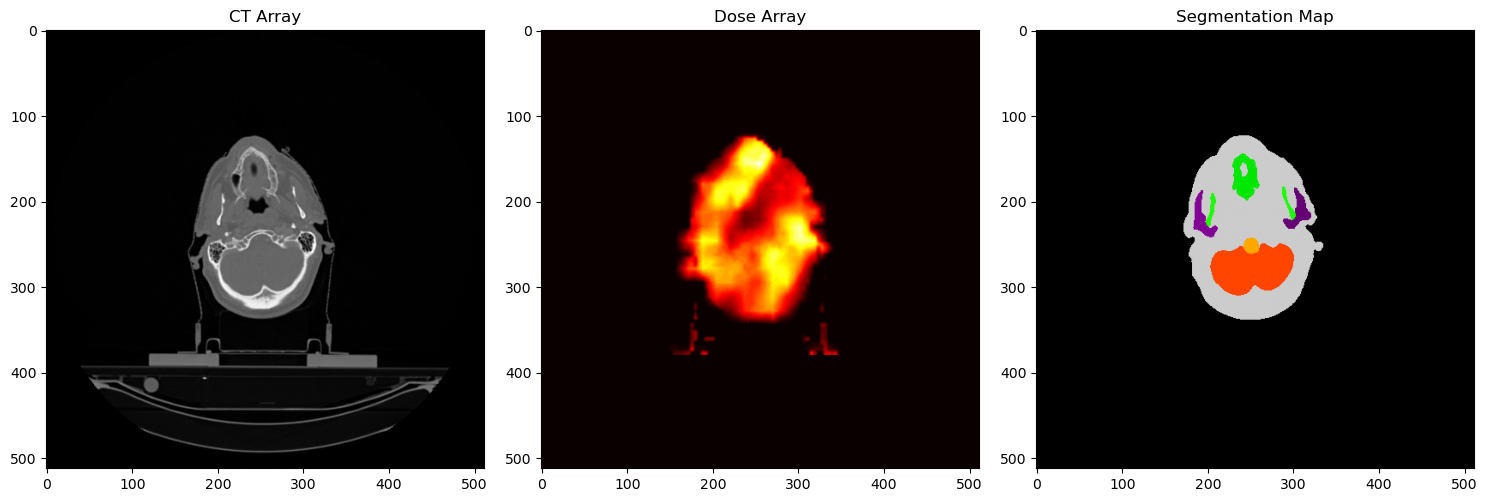

In [45]:
# quick visual inspection

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

slice_idx = 110  # which slice to plot

# Plot CT array
ct_array = convert_image_to_numpy(ct_image)
axes[0].imshow(ct_array[slice_idx, :, :], cmap='gray')
axes[0].set_title('CT Array')

# Plot Dose array
dose_array = convert_image_to_numpy(dose_image)
axes[1].imshow(dose_array[slice_idx, :, :], cmap='hot')
axes[1].set_title('Dose Array')

# Plot Segmentation map
segmentation_array = convert_image_to_numpy(segmentation_image)
axes[2].imshow(segmentation_array[slice_idx, :, :], cmap='nipy_spectral')
axes[2].set_title('Segmentation Map')

plt.tight_layout()
plt.show()

# resolution resampling

In [53]:
def change_image_spacing(image, new_spacing, is_segmentation=False):
    """
    Change the spacing of a SimpleITK image.

    Args:
        image: SimpleITK image to modify.
        new_spacing: List or tuple of new spacing values [x, y, z].

    Returns:
        resampled_image: SimpleITK image with updated spacing.
    """
    original_spacing = image.GetSpacing()
    original_size = image.GetSize()
    arr = sitk.GetArrayFromImage(image)

    # Calculate new size to maintain the same physical dimensions
    new_size = [
        int(round(original_size[i] * (original_spacing[i] / new_spacing[i])))
        for i in range(3)
    ]
    # define the interpolation method
    if is_segmentation:  # the values are discrete labels
        interpolator = sitk.sitkNearestNeighbor
    else:
        interpolator = sitk.sitkBSpline

    # Resample the image
    resampler = sitk.ResampleImageFilter()
    resampler.SetOutputSpacing(new_spacing)
    resampler.SetSize(new_size)
    resampler.SetOutputDirection(image.GetDirection())
    resampler.SetOutputOrigin(image.GetOrigin())
    resampler.SetInterpolator(interpolator) 
    resampler.SetDefaultPixelValue(np.float64(arr.min()))
    resampler.SetOutputPixelType(image.GetPixelID())

    # Execute resampling
    resampled_image = resampler.Execute(image)

    return resampled_image

# Example usage:
# new_image = change_sitk_image_spacing(image, [2, 2, 2])

In [60]:
new_spacing = [2.0, 2.0, 2.0]
resampled_ct_image = change_image_spacing(ct_image, new_spacing=new_spacing)
resampled_dose_image = change_image_spacing(dose_image, new_spacing=new_spacing)
resampled_segmentation_image = change_image_spacing(segmentation_image, new_spacing=new_spacing, is_segmentation=True)

print(f"Resampled CT spacing: {resampled_ct_image.GetSpacing()}, dimension : {resampled_ct_image.GetSize()}")
print(f"Resampled Dose spacing: {resampled_dose_image.GetSpacing()}, dimension : {resampled_dose_image.GetSize()}")
print(f"Resampled Segmentation spacing: {resampled_segmentation_image.GetSpacing()}, dimension : {resampled_segmentation_image.GetSize()}")

Resampled CT spacing: (2.0, 2.0, 2.0), dimension : (250, 250, 145)
Resampled Dose spacing: (2.0, 2.0, 2.0), dimension : (250, 250, 145)
Resampled Segmentation spacing: (2.0, 2.0, 2.0), dimension : (250, 250, 145)


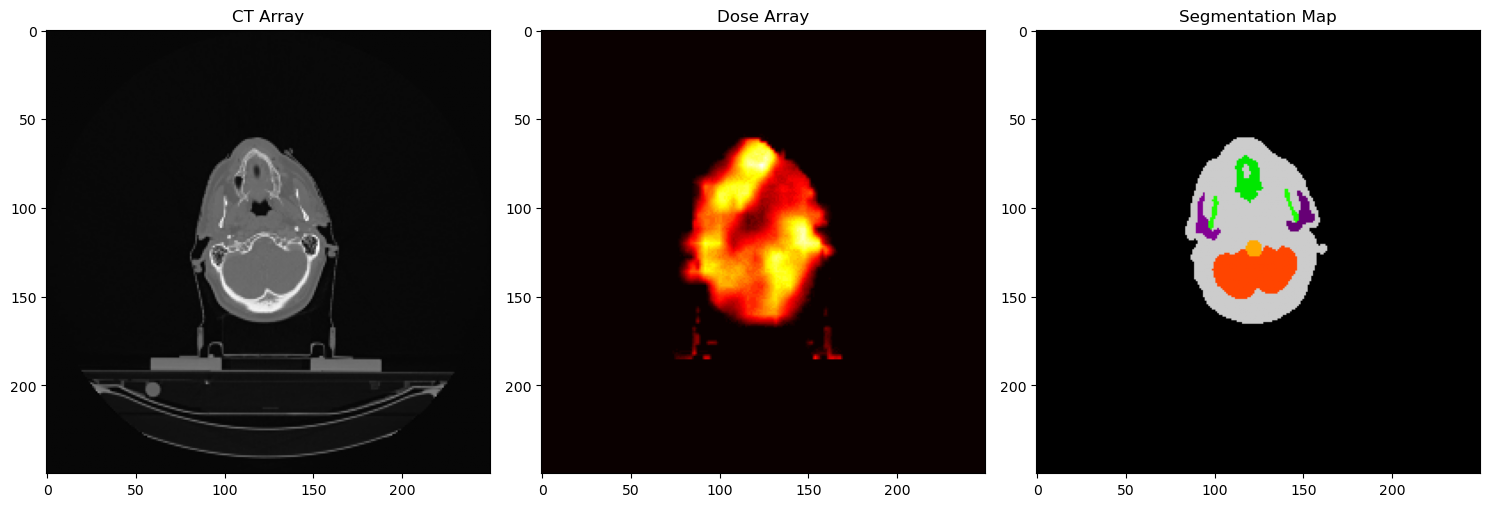

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

slice_idx = 110  # which slice to plot

# Plot CT array
ct_array = convert_image_to_numpy(resampled_ct_image)
axes[0].imshow(ct_array[slice_idx, :, :], cmap='gray')
axes[0].set_title('CT Array')

# Plot Dose array
dose_array = convert_image_to_numpy(resampled_dose_image)
axes[1].imshow(dose_array[slice_idx, :, :], cmap='hot')
axes[1].set_title('Dose Array')

# Plot Segmentation map
resampled_segmentation_array = convert_image_to_numpy(resampled_segmentation_image)
axes[2].imshow(resampled_segmentation_array[slice_idx, :, :], cmap='nipy_spectral')
axes[2].set_title('Segmentation Map')

plt.tight_layout()
plt.show()

# Cropping

In [ ]:
def determine_bounding_box(segmentation_image, cropping_struct_names, bb_size):
    """
    Determine the bounding box of a given label in a 3D segmentation array.

    Args:
        segmentation_image: 3D STK-Image with integer labels.
        label: Integer label to find the bounding box for.
    """
    segmentation_array = convert_image_to_numpy(segmentation_image)

    bounding_box_coords = {}
    for axis_idx, axis_name in enumerate(['z', 'y', 'x']):
        struct_names = cropping_struct_names[axis_name]  # get the OAR structure names for this axis
        struct_values = struct_names_to_values(struct_names, label_dict) # find the corresponding label values
        mask = get_segmentation_mask(segmentation_array, struct_values) # get the bounding box for these structures

        coords = np.where(mask > 0)[axis_idx]
        lower_struct_bound = coords.min()
        upper_struct_bound = coords.max()
        center = (lower_struct_bound + upper_struct_bound) // 2

        lower_BB_bound, upper_BB_bound = get_bounding_box_bounds(center, bb_size[axis_idx])

        bounding_box_coords[axis_name] = {'lower': lower_BB_bound, 'upper': upper_BB_bound, 'center': center}

    return bounding_box_coords


def get_segmentation_mask(segmentation_map, values):
    """
    Get segmentation mask (i.e. binary) with same shape as input segmentation_map.

    Args:
        segmentation_map (Numpy array): segmentation map
        values (list): list of integer label values to include in the mask

    Returns:
        mask (Numpy array): binary mask with same shape as segmentation_map

    """
    # Initialize mask
    mask = np.zeros_like(segmentation_map, dtype=np.uint8)
    for val in values:
        mask[segmentation_map == val] = 1
    return mask


def struct_names_to_values(struct_names_list, label_dict):
    """
    Convert structure names to their corresponding label values.

    Args:
        struct_names_list (list): list of structure names to convert.
        label_dict (dict): Dictionary mapping label values to structure names.

    Returns:
        values (list): List of label values corresponding to the input structure names.
    """
    
    values = []
    
    for name in struct_names_list:
        for key, val in label_dict.items():
            if val == name:
                #value_dict[name] = key
                values.append(key)    
    return values




def get_bounding_box_bounds(center_point: int, bb_length: int):
    """
    Calculate the lower and upper bounds of a bounding box given its center point and length.
    Args:
        center_point: Center point of the bounding box (int).
        bb_length: Length of the bounding box (int).
    Returns:
        lower_bound: Lower bound of the bounding box (int).
        upper_bound: Upper bound of the bounding box (int).
    """
    lower_bound = center_point - (bb_length // 2)
    upper_bound = center_point + (bb_length // 2) 

    return lower_bound, upper_bound

def crop_image(image:sitk.Image, bounding_box_coords: dict, bb_size: list):
    """
    Crop a SimpleITK image using bounding box coordinates. 

    Args:
        image: SimpleITK image to crop.
        bounding_box_coords: Dictionary with 'x', 'y', 'z' keys and 'lower', 'upper', 'center' subkeys.
        bb_size: List of desired bounding box size [size_x, size_y, size_z].

    Returns:
        cropped_image: Cropped SimpleITK image.
    """
    # Get bounding box limits
    x_lower, x_upper = bounding_box_coords['x']['lower'], bounding_box_coords['x']['upper']
    y_lower, y_upper = bounding_box_coords['y']['lower'], bounding_box_coords['y']['upper']
    z_lower, z_upper = bounding_box_coords['z']['lower'], bounding_box_coords['z']['upper']

    # Define the region of interest
    print([x_lower, y_lower, z_lower], bb_size, [x_upper, y_upper, z_upper])
    
    index = [x_lower, y_lower, z_lower]  # starting index (x, y, z)
    size = [bb_size[0], bb_size[1], bb_size[2]]
    index = [int(x) for x in index]
    size = [int(x) for x in size]

    cropped_image = sitk.RegionOfInterest(image, size=size, index=index)

    return cropped_image






# original Hung code:
# Z = parotids, lower structures ('crico', 'thyroid') and mandible
# Y = parotids
# X = parotids, submandibulars

# dictionary defining which structures to use for cropping in each axis
cropping_struct_names = {
    'z' : ["Parotid_L", "Parotid_R", "Crico", "Thyroid", "Mandible"],
    'x' : ["Parotid_L", "Parotid_R"],
    'y' : ["Parotid_L", "Parotid_R", "Submandibular_L", "Submandibular_R"]
}

# define the size of the output array
bb_size = [100, 100, 100] # [x, y, z] dimensions


bounding_box_coords_dict = determine_bounding_box(resampled_segmentation_image, cropping_struct_names, bb_size)

print(bounding_box_coords_dict)

cropped_ct_image = crop_image(resampled_ct_image, bounding_box_coords_dict, bb_size)
cropped_dose_image = crop_image(resampled_dose_image, bounding_box_coords_dict, bb_size)
cropped_segmentation_image = crop_image(resampled_segmentation_image, bounding_box_coords_dict, bb_size)


{'z': {'lower': 22, 'upper': 122, 'center': 72}, 'y': {'lower': 54, 'upper': 154, 'center': 104}, 'x': {'lower': 72, 'upper': 172, 'center': 122}}
[72, 54, 22] [100, 100, 100] [172, 154, 122]
[72, 54, 22] [100, 100, 100] [172, 154, 122]
[72, 54, 22] [100, 100, 100] [172, 154, 122]


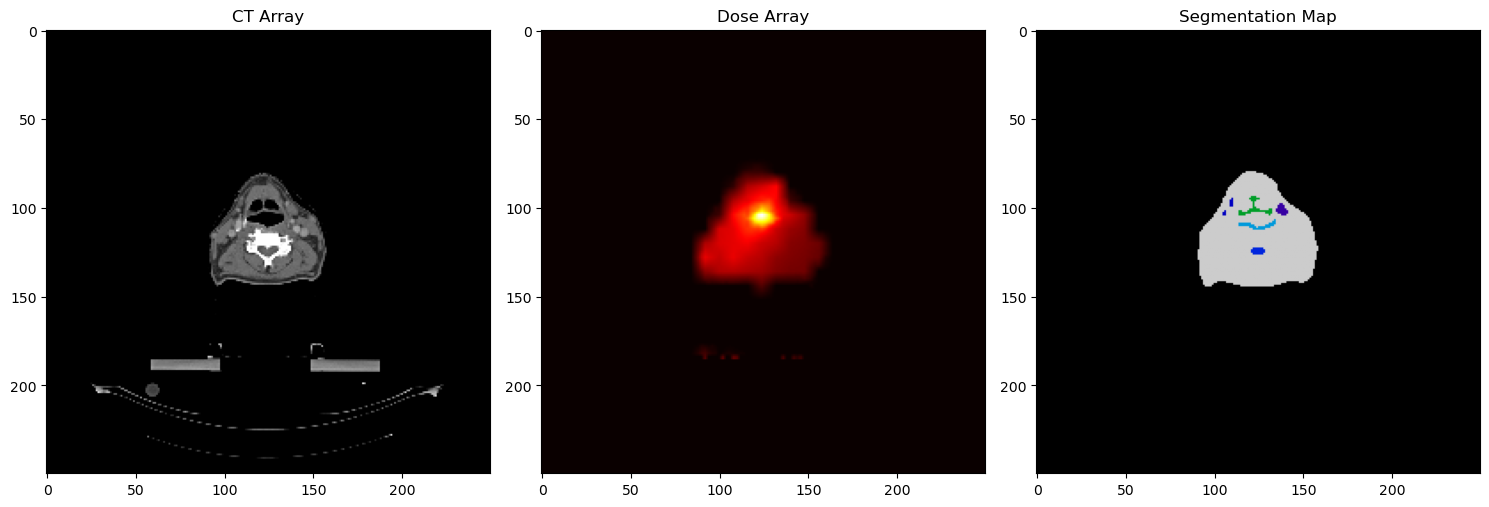

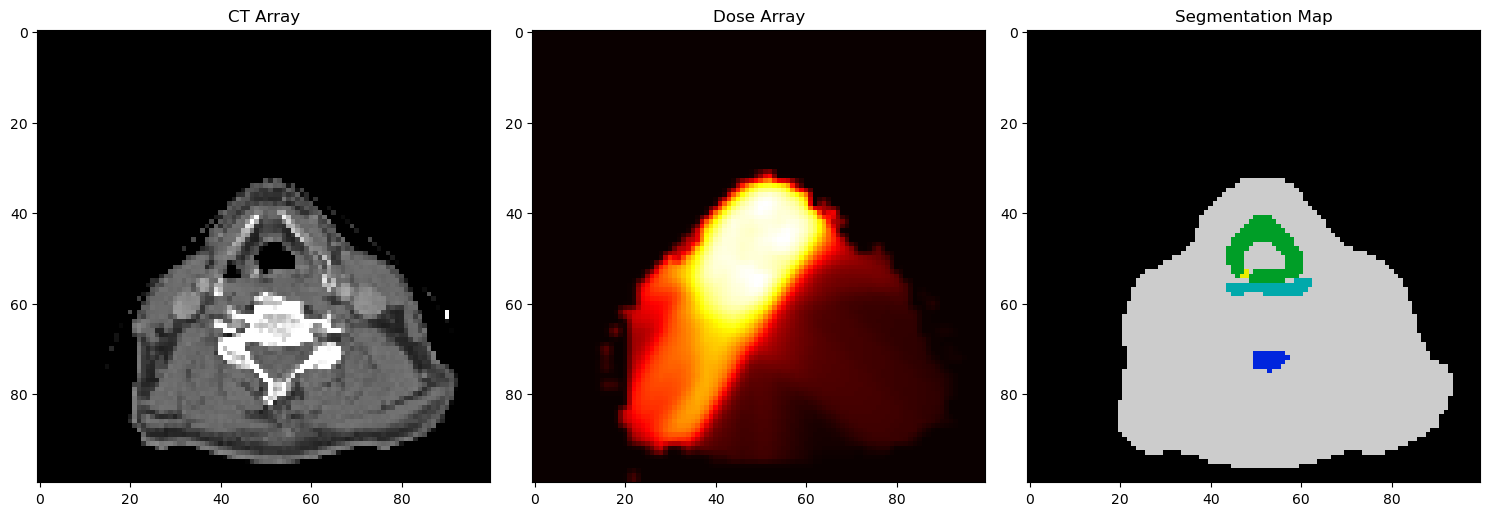

In [215]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

slice_idx = 72  # which slice to plot

# Plot CT array
ct_array = convert_image_to_numpy(resampled_ct_image)
ct_array = np.clip(ct_array, -200, 400)
axes[0].imshow(ct_array[slice_idx, :, :], cmap='gray')
axes[0].set_title('CT Array')

# Plot Dose array
dose_array = convert_image_to_numpy(resampled_dose_image)
axes[1].imshow(dose_array[slice_idx, :, :], cmap='hot')
axes[1].set_title('Dose Array')

# Plot Segmentation map
resampled_segmentation_array = convert_image_to_numpy(resampled_segmentation_image)
axes[2].imshow(resampled_segmentation_array[slice_idx, :, :], cmap='nipy_spectral')
axes[2].set_title('Segmentation Map')

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

slice_idx = 40  # which slice to plot

# Plot CT array
ct_array = convert_image_to_numpy(cropped_ct_image)
ct_array = np.clip(ct_array, -200, 400)
axes[0].imshow(ct_array[slice_idx, :, :], cmap='gray')
axes[0].set_title('CT Array')

# Plot Dose array
dose_array = convert_image_to_numpy(cropped_dose_image)
axes[1].imshow(dose_array[slice_idx, :, :], cmap='hot')
axes[1].set_title('Dose Array')

# Plot Segmentation map
resampled_segmentation_array = convert_image_to_numpy(cropped_segmentation_image)
axes[2].imshow(resampled_segmentation_array[slice_idx, :, :], cmap='nipy_spectral')
axes[2].set_title('Segmentation Map')

plt.tight_layout()
plt.show()

(100, 100, 100)

# Normalisation

In [222]:
def normalize_sitk_image(image, normalisation_params:dict):
    """
    Normalize a SimpleITK image to a specified range [new_min, new_max], with optional clipping.

    Args:
        image: SimpleITK image to normalize.
        old_min: Minimum value of the original range.
        old_max: Maximum value of the original range.
        new_min: Minimum value of the normalized range (default: 0.0).
        new_max: Maximum value of the normalized range (default: 1.0).
        clip_min: Minimum value to clip the image to (optional).
        clip_max: Maximum value to clip the image to (optional).

    Returns:
        normalized_image: Normalized SimpleITK image.
    """
    # Convert image to numpy array
    image_array = sitk.GetArrayFromImage(image).astype(float)

    # Clip the values if clip_min and/or clip_max are provided
    clip_min = normalisation_params['a_min']
    clip_max = normalisation_params['a_max']
    
    new_min = normalisation_params['a_min']
    new_max = normalisation_params['a_max']

    image_array = np.clip(image_array, a_min=clip_min, a_max=clip_max)
    normalized_array = (image_array - new_min) / (new_max - new_min)

    # Convert back to SimpleITK image
    normalized_image = sitk.GetImageFromArray(normalized_array)

    # Copy metadata from the original image
    normalized_image.SetSpacing(image.GetSpacing())
    normalized_image.SetOrigin(image.GetOrigin())
    normalized_image.SetDirection(image.GetDirection())

    return normalized_image



normalisation_params = {
    'ct' : {
        'a_min' : -200,
        'a_max' : 400,
        'b_min' : 0,
        'b_max' : 1
    },
    'dose' :{
        'a_min' : 0,
        'a_max' : 8000,
        'b_min' : 0,
        'b_max' : 1
    },
}

# Example usage:
normalized_ct_image = normalize_sitk_image(cropped_ct_image, normalisation_params['ct'])
normalized_dose_image = normalize_sitk_image(cropped_dose_image, normalisation_params['dose'])



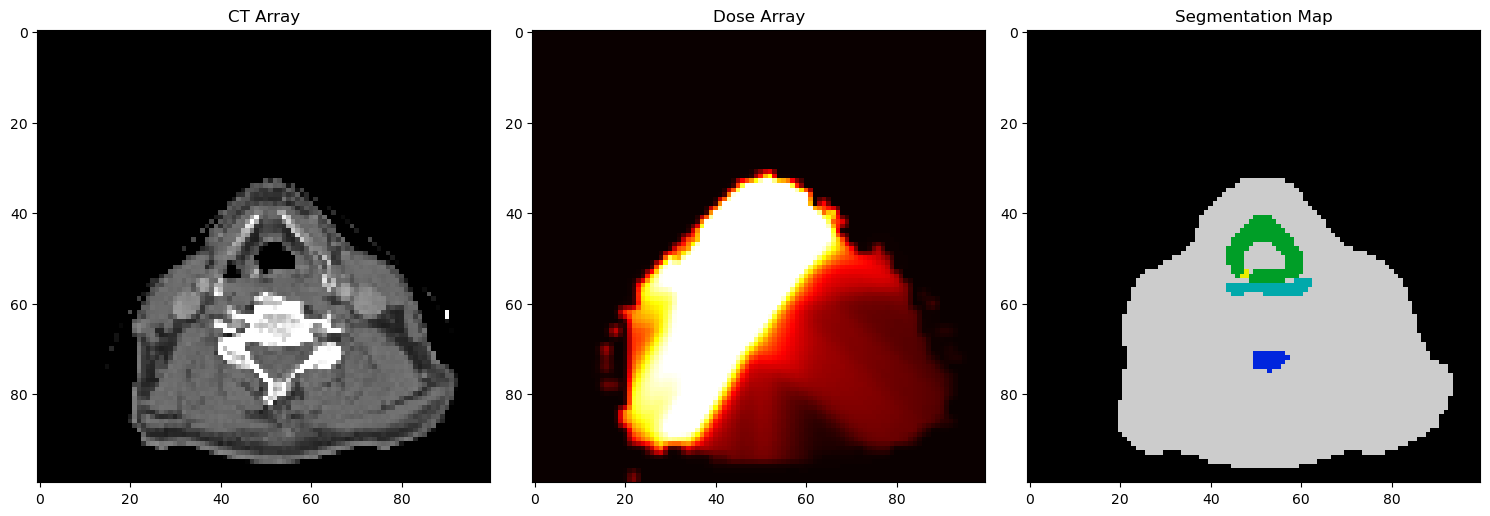

In [226]:

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

slice_idx = 40  # which slice to plot

# Plot CT array
ct_array = convert_image_to_numpy(normalized_ct_image)
axes[0].imshow(ct_array[slice_idx, :, :], cmap='gray', interpolation=None)
axes[0].set_title('CT Array')

# Plot Dose array
dose_array = convert_image_to_numpy(normalized_dose_image)
axes[1].imshow(dose_array[slice_idx, :, :], cmap='hot', interpolation=None)
axes[1].set_title('Dose Array')

# Plot Segmentation map
resampled_segmentation_array = convert_image_to_numpy(cropped_segmentation_image)
axes[2].imshow(resampled_segmentation_array[slice_idx, :, :], cmap='nipy_spectral', interpolation=None)
axes[2].set_title('Segmentation Map')

plt.tight_layout()
plt.show()